# 08 — Validación externa en HUPA-UCM, sin reentrenar

**Objetivo**: responder a las dos primeras preguntas de la Fase 8 (capítulo 4 de la memoria)
con el modelo final de OhioT1DM aplicado tal cual a otro hospital, otro sensor y otra población:

- **E1**: ¿mantiene el *ensemble* su error y su capacidad de detección?
- **E2**: ¿el α elegido en la validación de Ohio sigue dando ≈ 1 falsa alarma al día, o hay que
  recalibrarlo en cada centro?

**Protocolo**: el de OhioT1DM (tolerancia de 15 min, eventos puntuables, recall por eventos con
IC bootstrap), con tres adaptaciones al FreeStyle Libre descritas en el notebook 07 y en
`tfm.data.hupa`. Primera: un evento son ≥ 2 lecturas reales seguidas < 70. Segunda: cada
predicción se ancla en una lectura real, es decir, una cada 15 min. Tercera: por eso las alarmas
separadas ≤ 20 min forman un mismo episodio (`episode_gap_min`).

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tfm.data import hupa
from tfm.eval.alarm import operating_curve, predictions_from_experiment
from tfm.eval.compare import load_result
from tfm.eval.protocol import scorable_events_by_patient
from tfm.training import external as ext
from tfm.viz import FIG_WIDTH_FULL, INK, RAMPS, ROLE, save_figure, set_style
from tfm.viz.plots import plot_operating_curves_compared

set_style()
pd.set_option("display.width", 160)

MAIN = "20261002-hupa-zeroshot"
SENS = {"is_imputed en toda celda interpolada": "20261002-hupa-zeroshot-imputados",
        "escalador reajustado en HUPA": "20261002-hupa-zeroshot-escalador"}
OHIO_ENS = "20260930-global-bigru-ensemble"
OHIO_PERS = "20260915-baseline-persistencia"
HORIZONS = (30, 60)
COLORS = {"OhioT1DM (test oficial)": ROLE["referencia"], "HUPA-UCM": ROLE["modelo"]}

res = load_result(MAIN)
ohio = load_result(OHIO_ENS)
ohio_pers = load_result(OHIO_PERS)
groups = res["groups"]
print({g: len(p) for g, p in groups.items()})
print("α de Ohio (1 FA/día):", {h: res["ohio_alpha"][h]["1.0"] for h in res["ohio_alpha"]})

{'principal': 13, 'principal_CSII': 10, 'principal_MDI': 3, 'largos': 3, 'parcial': 5, 'sin_registro': 2}
α de Ohio (1 FA/día): {'30': 0.3, '60': 0.4}


El grupo **principal** son los 13 pacientes con el tratamiento registrado completo y un
seguimiento comparable al de Ohio (≤ 30 días). Los tres pacientes largos, los de registro parcial
y los que no registraron el tratamiento se informan aparte. El α viene de la validación de Ohio:
0,3 a 30 min y 0,4 a 60 min con 1 FA/día.

## 1. Eventos puntuables

In [2]:
ev = pd.DataFrame({
    "encontrados": {s: sum(res["n_events_found"][s][p] for p in groups["principal"]) for s in res["scopes"]},
    "puntuables": {s: sum(res["n_events_scorable"][s][p] for p in groups["principal"]) for s in res["scopes"]},
})
ev["% puntuable"] = (100 * ev["puntuables"] / ev["encontrados"]).round(1)
ev

,encontrados,puntuables,% puntuable
all,210,174,82.9
adapt,149,125,83.9
test,61,47,77.0


Puntúan **174 de los 210 eventos** de la serie (82,9 %) y **47 de los 61** del test (77,0 %). Los
que faltan empiezan tras un hueco del sensor o en la primera hora de una parte, donde ninguna
ventana tiene 60 min de historia. En Ohio puntuaban 61 de 69 (88 %). La proporción es algo menor
aquí porque los segmentos del Libre son más cortos y las ventanas solo se anclan en lecturas reales.

## 2. E1: error y detección sin reentrenar

In [3]:
def row(model, h, scope="all", group="principal"):
    s = res["regression"][model][scope][group][str(h)]["summary"]
    r = s["pooled_event_recall"]
    return {"RMSE": s["rmse_pooled"], "Clarke A+B (%)": s["clarke_AB_pooled"],
            "Parkes D+E (%)": s["parkes_DE_pooled"],
            "recall μ<70": r["point"], "IC95 %": f"{r['lo']:.3f}–{r['hi']:.3f}", "eventos": r["n"]}

models = ["persistencia", "ridge_global_ohio", "bigru_seed0", "bigru_seed1", "bigru_seed2", "ensemble"]
e1 = pd.concat({h: pd.DataFrame({m: row(m, h) for m in models}).T for h in HORIZONS}, names=["PH", "modelo"])
seeds = e1.loc[(slice(None), ["bigru_seed0", "bigru_seed1", "bigru_seed2"]), "RMSE"].groupby(level=0)
print("RMSE de las semillas (media ± DE):",
      {h: f"{seeds.mean()[h]:.2f} ± {seeds.std()[h]:.2f}" for h in HORIZONS})
e1.round(3)

RMSE de las semillas (media ± DE): {30: '20.36 ± 0.11', 60: '36.49 ± 0.17'}


RMSE Clarke A+B (%) Parkes D+E (%) recall μ<70       IC95 % eventos
PH modelo                                                                                     
30 persistencia       24.965066      97.947966            0.0     0.08046  0.046–0.121     174
   ridge_global_ohio   21.40211      97.266398            0.0    0.287356  0.224–0.356     174
   bigru_seed0        20.246414      96.614144            0.0    0.224138  0.167–0.287     174
   bigru_seed1        20.362279        97.4203            0.0    0.327586  0.259–0.397     174
   bigru_seed2         20.45904      97.339685            0.0    0.293103  0.230–0.362     174
   ensemble           20.253163       97.14181            0.0    0.252874  0.190–0.322     174
60 persistencia       41.833321      93.755955       0.263833    0.149425  0.098–0.201     174
   ridge_global_ohio  37.867049      91.168926       0.146574    0.034483  0.011–0.063     174
   bigru_seed0        36.394218      91.513375        0.10993    0.045977  0.017–0.080     174
   bigru_seed1         36.38793      91.550018       0.139245    0.005747  0.000–0.017     174
   bigru_seed2        36.681291      91.286185       0.139245    0.017241  0.000–0.040     174
   ensemble            36.34299      91.418102       0.124588    0.017241  0.000–0.040     174

Sobre la serie de los 13 pacientes, el *ensemble* tiene un RMSE de **20,25 / 36,34 mg/dL** (30 / 60
min). Las tres semillas coinciden: 20,36 ± 0,11 y 36,49 ± 0,17. Hay dos hallazgos de Ohio que se
repiten:

- **El encogimiento hacia la media**: con la regla μ < 70, el *ensemble* solo detecta el 25,3 %
  de los eventos a 30 min (IC 19,0–32,2 %).
- **El mejor RMSE no es el mejor detector**: el ridge global, peor en error, detecta más con μ < 70
  (28,7 %).

Parkes D+E no pasa del 0,12 % en ningún modelo.

In [4]:
def ohio_row(h):
    s = ohio["by_horizon"][str(h)]["summary"]
    p = ohio_pers["by_horizon"][str(h)]["summary"]
    return {"RMSE ensemble": s["rmse_pooled"], "RMSE persistencia": p["rmse_pooled"],
            "Clarke A+B (%)": s["clarke_AB_pooled"], "Parkes D+E (%)": s["parkes_DE_pooled"]}

def hupa_row(h):
    s = res["regression"]["ensemble"]["all"]["principal"][str(h)]["summary"]
    p = res["regression"]["persistencia"]["all"]["principal"][str(h)]["summary"]
    return {"RMSE ensemble": s["rmse_pooled"], "RMSE persistencia": p["rmse_pooled"],
            "Clarke A+B (%)": s["clarke_AB_pooled"], "Parkes D+E (%)": s["parkes_DE_pooled"]}

cmp = pd.concat({h: pd.DataFrame({"OhioT1DM": ohio_row(h), "HUPA-UCM": hupa_row(h)}).T for h in HORIZONS},
                names=["PH", "cohorte"])
# Skill over persistence: removes how hard each cohort is to predict to begin with.
cmp["mejora sobre persistencia (%)"] = 100 * (1 - cmp["RMSE ensemble"] / cmp["RMSE persistencia"])
cmp.round(2)

RMSE ensemble  RMSE persistencia  Clarke A+B (%)  Parkes D+E (%)  mejora sobre persistencia (%)
PH cohorte                                                                                                  
30 OhioT1DM          18.84              23.50           98.86            0.00                          19.82
   HUPA-UCM          20.25              24.97           97.14            0.00                          18.87
60 OhioT1DM          31.29              38.55           96.78            0.05                          18.82
   HUPA-UCM          36.34              41.83           91.42            0.12                          13.12

El RMSE sube respecto a Ohio, pero **también sube el de la persistencia** (23,50 → 24,97 y 38,55
→ 41,83): HUPA es más difícil de predecir de partida. La comparación justa es la **mejora sobre
la persistencia**:

- **A 30 min es prácticamente la misma** (19,8 % en Ohio y 18,9 % en HUPA): el modelo generaliza.
- **A 60 min cae** del 18,8 % al 13,1 %, y Clarke A+B baja de 96,8 % a 91,4 %.

Una explicación compatible con el notebook 07: a 60 min la predicción depende más del
tratamiento registrado, que es la entrada más desplazada (la basal, −1,07 DE de Ohio).

In [5]:
tests = []
for h in HORIZONS:
    for other in ("persistencia", "ridge_global_ohio"):
        t = ext.paired_test(res, "ensemble", other, horizon_min=h)
        tests.append({"PH": h, "frente a": other, **{k: t[k] for k in ("n", "median_a", "median_b", "p_value")}})
pd.DataFrame(tests).round(4)

,PH,frente a,n,median_a,median_b,p_value
0,30,persistencia,13,19.7840,24.4726,0.0012
1,30,ridge_global_ohio,13,19.7840,21.9636,0.0007
2,60,persistencia,13,35.9233,40.8813,0.0134
3,60,ridge_global_ohio,13,35.9233,39.0240,0.0061


Por paciente (n = 13, Wilcoxon pareado), el *ensemble* tiene menor RMSE que la persistencia
(p = 0,0012 a 30 min; 0,013 a 60) y que el ridge global ajustado en Ohio (p = 0,0007; 0,006). Con
la corrección de Holm sobre las cuatro comparaciones, todas siguen por debajo de 0,05.

[PosixPath('memoria/figuras/08_hupa_mejora_por_paciente.pdf'),
 PosixPath('memoria/figuras/08_hupa_mejora_por_paciente.png')]

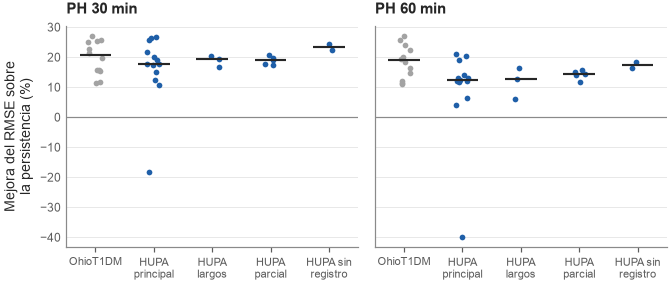

In [6]:
def skill_ohio(h):
    e = pd.DataFrame(ohio["by_horizon"][str(h)]["per_patient"]).set_index("patient")["rmse"]
    p = pd.DataFrame(ohio_pers["by_horizon"][str(h)]["per_patient"]).set_index("patient")["rmse"]
    return 100 * (1 - e / p.loc[e.index])

def skill_hupa(h, group):
    e = ext.per_patient(res, "ensemble", "all", group, h).set_index("patient")["rmse"]
    p = ext.per_patient(res, "persistencia", "all", group, h).set_index("patient")["rmse"]
    return 100 * (1 - e / p)

# The x position names the group, so colour only separates the reference cohort
# from HUPA; it is not asked to tell five groups apart.
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.8), sharey=True)
rng = np.random.default_rng(0)
cols = [("OhioT1DM", None), ("HUPA\nprincipal", "principal"), ("HUPA\nlargos", "largos"),
        ("HUPA\nparcial", "parcial"), ("HUPA sin\nregistro", "sin_registro")]
for ax, h in zip(axes, HORIZONS):
    for i, (label, group) in enumerate(cols):
        v = skill_ohio(h) if group is None else skill_hupa(h, group)
        color = ROLE["referencia"] if group is None else ROLE["modelo"]
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=14, color=color, zorder=3)
        ax.hlines(v.median(), i - 0.27, i + 0.27, color=INK["texto"], lw=1.4, zorder=4)
    ax.axhline(0, color=INK["tenue"], lw=0.8)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([c[0] for c in cols], fontsize=7)
    ax.set_title(f"PH {h} min")
axes[0].set_ylabel("Mejora del RMSE sobre\nla persistencia (%)")
fig.tight_layout()
save_figure(fig, "08_hupa_mejora_por_paciente")

**Figura 08_hupa_mejora_por_paciente.** Cada punto es un paciente; la barra, la mediana del grupo. A
30 min las medianas de Ohio y del grupo principal de HUPA son muy parecidas. Los grupos con
registro parcial o sin registro mejoran a la persistencia igual o más: a 30 min el modelo se apoya
sobre todo en la dinámica de la glucosa. **Un solo paciente, HUPA0022P, empeora a la persistencia**
(−18 % a 30 min y −40 % a 60). Se analiza a continuación.

In [7]:
# Diagnóstico post hoc del único paciente que empeora a la persistencia.
worst = {h: (ext.per_patient(res, "ensemble", "all", "principal", h).set_index("patient")["rmse"]
             / ext.per_patient(res, "persistencia", "all", "principal", h).set_index("patient")["rmse"])
         for h in HORIZONS}
peor = worst[30].idxmax()
pers = ext.per_patient(res, "persistencia", "all", "principal", 30).set_index("patient").loc[peor, "rmse"]
variantes = {"tal cual": (), "sin hidratos (cob, carbs)": ("cob", "carbs"),
             "sin bolos (iob, bolus_dose)": ("iob", "bolus_dose"), "sin basal": ("basal_rate",),
             "solo glucosa y hora": ("cob", "carbs", "iob", "bolus_dose", "basal_rate", "pump_suspended")}
abl = pd.DataFrame({k: ext.ablate_inputs(peor, v) for k, v in variantes.items()}).T
abl.columns = [f"RMSE {h} min" for h in abl.columns]
print(f"Paciente: {peor}; RMSE de la persistencia a 30 min: {pers:.1f}")
print(hupa.load_summary().set_index("patient").loc[peor, ["treatment", "basal_u_per_day", "bolus_u_per_day", "carbs_g_per_day"]].to_dict())
abl.round(1)

Paciente: HUPA0022P; RMSE de la persistencia a 30 min: 12.7
{'treatment': 'CSII', 'basal_u_per_day': 38.7, 'bolus_u_per_day': 28.8, 'carbs_g_per_day': 289.6}


,RMSE 30 min,RMSE 60 min
tal cual,15.0,29.2
"sin hidratos (cob, carbs)",12.3,23.9
"sin bolos (iob, bolus_dose)",16.2,31.7
sin basal,12.5,22.7
solo glucosa y hora,11.5,21.5


**Diagnóstico *post hoc* de HUPA0022P.** Su glucosa es muy estable (la persistencia ya consigue 12,7
mg/dL a 30 min) y su registro de tratamiento es el mayor de la cohorte: 38,7 U/día de basal y 290
g/día de hidratos. **Si se anulan los hidratos o la basal, el error baja al nivel de la
persistencia, y con solo glucosa y hora la supera.** El fallo no viene de la señal de glucosa: viene
de unas entradas de tratamiento que caen fuera de la relación que el modelo aprendió en Ohio.

Es un diagnóstico sobre un paciente, no un resultado. Su lectura para la memoria es una
limitación: el modelo multivariante depende de que el registro del tratamiento sea comparable al
de su entrenamiento.

In [8]:
def group_row(group, h, budget="1.0"):
    s = res["regression"]["ensemble"]["all"][group][str(h)]["summary"]
    a = res["alarm"]["ensemble"][str(h)][budget][group]["ohio_alpha"]["all"]
    return {"pacientes": s["n_patients"], "RMSE": s["rmse_pooled"],
            "recall (α Ohio)": a["recall"]["point"],
            "IC95 %": f"{a['recall']['lo']:.3f}–{a['recall']['hi']:.3f}",
            "eventos": a["recall"]["n"], "FA/día": a["false_alarms_per_day"]}

order = ["principal", "principal_CSII", "principal_MDI", "largos", "parcial", "sin_registro"]
pd.concat({h: pd.DataFrame({g: group_row(g, h) for g in order if groups[g]}).T for h in HORIZONS},
          names=["PH", "grupo"]).round(3)

pacientes       RMSE recall (α Ohio)       IC95 % eventos    FA/día
PH grupo                                                                             
30 principal             13  20.253163        0.844828  0.793–0.897     174  1.029423
   principal_CSII        10  20.750759        0.827815  0.768–0.887     151  1.125728
   principal_MDI          3  18.422102        0.956522  0.870–1.000      23  0.697607
   largos                 3  15.610036        0.820339  0.792–0.851     590  0.964637
   parcial                5  23.479936        0.942857  0.857–1.000      35  0.981261
   sin_registro           2  20.658335        0.896552  0.793–1.000      29  0.679334
60 principal             13   36.34299        0.091954  0.052–0.138     174  0.489604
   principal_CSII        10  37.085208        0.092715  0.046–0.139     151  0.477827
   principal_MDI          3  33.640054        0.086957  0.000–0.217      23  0.530181
   largos                 3  27.886557        0.081356  0.061–0.105     590   0.43556
   parcial                5  40.900067        0.085714  0.000–0.171      35  0.665855
   sin_registro           2     38.531        0.068966  0.000–0.172      29  0.415149

Con el α de Ohio y 1 FA/día:

- **A 30 min la alarma detecta entre el 82 % y el 96 % de los eventos en todos los grupos**, con
  0,68–1,13 FA/día.
- En los tres pacientes largos, el recall es 0,820 (IC 0,792–0,851) sobre **590 eventos** con 0,96
  FA/día: el intervalo más estrecho de todo el TFM.
- La diferencia CSII/MDI no es distinguible (MDI tiene solo 23 eventos).
- **El registro parcial o ausente no degrada la alarma a 30 min**, coherente con la figura anterior.
- A 60 min no pasa del 9 % en ningún grupo.

## 3. E2: ¿se transfiere el umbral α?

In [9]:
rows = []
for h in HORIZONS:
    for b in ("0.5", "1.0", "2.0"):
        a = res["alarm"]["ensemble"][str(h)][b]["principal"]
        o = ohio["alarm"][str(h)][b]
        for label, block in (("Ohio (test oficial)", {"alpha": o["alpha"], "recall": o["recall"],
                                                      "false_alarms_per_day": o["false_alarms_per_day"]}),
                             ("HUPA serie, α Ohio", a["ohio_alpha"]["all"]),
                             ("HUPA test, α Ohio", a["ohio_alpha"]["test"]),
                             ("HUPA test, α recalibrado", a["recalibrated"]["test"])):
            r = block["recall"]
            rows.append({"PH": h, "presupuesto FA/día": float(b), "escenario": label,
                         "α": block["alpha"], "recall": r["point"],
                         "IC95 %": f"{r['lo']:.3f}–{r['hi']:.3f}", "eventos": r["n"],
                         "FA/día": block["false_alarms_per_day"]})
e2 = pd.DataFrame(rows).set_index(["PH", "presupuesto FA/día", "escenario"])
e2.round(3)

α  recall       IC95 %  eventos  FA/día
PH presupuesto FA/día escenario                                                           
30 0.5                Ohio (test oficial)       0.50   0.115  0.049–0.197       61   0.308
                      HUPA serie, α Ohio        0.50   0.253  0.190–0.322      174   0.433
                      HUPA test, α Ohio         0.50   0.234  0.128–0.362       47   0.417
                      HUPA test, α recalibrado  0.50   0.234  0.128–0.362       47   0.417
   1.0                Ohio (test oficial)       0.30   0.836  0.738–0.918       61   0.964
                      HUPA serie, α Ohio        0.30   0.845  0.793–0.897      174   1.029
                      HUPA test, α Ohio         0.30   0.872  0.766–0.957       47   0.834
                      HUPA test, α recalibrado  0.40   0.511  0.362–0.660       47   0.459
   2.0                Ohio (test oficial)       0.20   0.951  0.885–1.000       61   1.644
                      HUPA serie, α Ohio        0.20   0.937  0.897–0.971      174   1.481
                      HUPA test, α Ohio         0.20   1.000  1.000–1.000       47   1.334
                      HUPA test, α recalibrado  0.15   1.000  1.000–1.000       47   1.772
60 0.5                Ohio (test oficial)       0.50   0.033  0.000–0.082       61   0.227
                      HUPA serie, α Ohio        0.50   0.017  0.000–0.040      174   0.213
                      HUPA test, α Ohio         0.50   0.021  0.000–0.064       47   0.104
                      HUPA test, α recalibrado  0.50   0.021  0.000–0.064       47   0.104
   1.0                Ohio (test oficial)       0.40   0.066  0.016–0.131       61   0.421
                      HUPA serie, α Ohio        0.40   0.092  0.052–0.138      174   0.490
                      HUPA test, α Ohio         0.40   0.106  0.021–0.191       47   0.334
                      HUPA test, α recalibrado  0.40   0.106  0.021–0.191       47   0.334
   2.0                Ohio (test oficial)       0.25   0.361  0.246–0.475       61   1.344
                      HUPA serie, α Ohio        0.25   0.333  0.264–0.408      174   1.393
                      HUPA test, α Ohio         0.25   0.362  0.234–0.511       47   1.084
                      HUPA test, α recalibrado  0.20   0.489  0.340–0.638       47   1.418

**Sí, a 30 min.** Con el α = 0,3 elegido en la validación de Ohio, la serie de HUPA da un recall de
**0,845 (IC95 % 0,793–0,897) con 1,03 FA/día sobre 174 eventos**, frente a 0,836 (0,738–0,918) con
0,96 FA/día en el test de Ohio. El presupuesto se respeta con un 3 % de margen, en una cohorte con
el doble de hipoglucemia y otro sensor. Con los presupuestos de 0,5 y 2 FA/día ocurre lo mismo:
0,43 frente a 0,31 FA/día, y 1,48 frente a 1,64. A 60 min la alarma es igual de inútil en las dos
cohortes (0,092 frente a 0,066).

In [10]:
pd.DataFrame({(h, b): {k: res["alarm"]["ensemble"][str(h)][b]["principal"]["recalibrated"][k]
                      for k in ("alpha", "within_budget", "adapt_recall", "adapt_false_alarms_per_day")}
              for h in HORIZONS for b in ("0.5", "1.0", "2.0")}).T

alpha within_budget adapt_recall adapt_false_alarms_per_day
30 0.5   0.5          True        0.264                   0.445328
   1.0   0.4          True        0.592                   0.618006
   2.0  0.15          True        0.968                   1.708606
60 0.5   0.5          True        0.016                   0.263561
   1.0   0.4          True        0.088                   0.563476
   2.0   0.2          True         0.52                   1.872195

**Recalibrar α con el 70 % inicial de HUPA empeora el resultado.** A 1 FA/día, en la parte de
adaptación α = 0,3 se pasa del presupuesto, así que se elige 0,4 (0,62 FA/día). En el test, el recall
cae a **0,511 (0,362–0,660), frente a 0,872 (0,766–0,957) con el α de Ohio** sobre los mismos 47
eventos.

La causa es la misma que en las semillas de Ohio. La rejilla de α es gruesa, y el paso de 0,3 a
0,4 cae en el tramo empinado de la curva: el recall baja de 0,85 a 0,57. Elegir con unos 9 días por
paciente añade ruido. **El α viaja con el modelo; recalibrarlo con pocos días locales no ayuda.**
La única ganancia aparente (60 min, 2 FA/día: 0,489 frente a 0,362) llega con 1,42 FA/día y a un
nivel de recall que no sirve clínicamente.

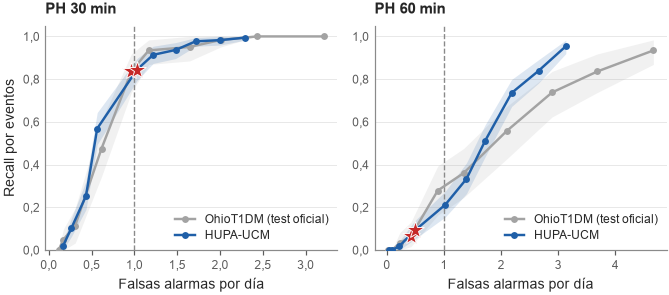

OhioT1DM (test oficial)                                                  HUPA-UCM                                                 
                           30                          60                            30                          60                     
                       recall false_alarms_per_day recall false_alarms_per_day   recall false_alarms_per_day recall false_alarms_per_day
alpha                                                                                                                                   
0.05                    1.000                3.215  0.934                4.664    0.994                2.291  0.954                3.132
0.10                    1.000                2.429  0.836                3.684    0.983                2.002  0.839                2.655
0.15                    0.984                2.008  0.738                2.891    0.977                1.714  0.736                2.184
0.20                    0.951                1.644  0.557                2.097    0.937                1.481  0.511                1.720
0.25                    0.934                1.166  0.361                1.344    0.914                1.218  0.333                1.393
0.30                    0.836                0.964  0.279                0.891    0.845                1.029  0.213                1.023
0.40                    0.475                0.615  0.066                0.421    0.569                0.565  0.092                0.490
0.50                    0.115                0.308  0.033                0.227    0.253                0.433  0.017                0.213
0.60                    0.049                0.170  0.000                0.089    0.103                0.264  0.000                0.088
0.70                    0.000                0.113  0.000                0.016    0.017                0.163  0.000                0.031

In [11]:
frames = hupa.load_frames()
hupa_by_h = {h: [p for p in preds if p.patient in groups["principal"]]
             for h, preds in ext.load_predictions(MAIN, "ensemble", "all").items()}
hupa_events = ext.scorable_events(frames, hupa_by_h, "all")
ohio_by_h = predictions_from_experiment(OHIO_ENS)
ohio_events = scorable_events_by_patient(ohio_by_h)
curves = {"OhioT1DM (test oficial)": {h: operating_curve(ohio_by_h[h], ohio_events) for h in HORIZONS},
          "HUPA-UCM": {h: operating_curve(hupa_by_h[h], hupa_events) for h in HORIZONS}}
alpha_ohio = {h: ohio["alarm"][str(h)]["1.0"]["alpha"] for h in HORIZONS}
fig = plot_operating_curves_compared(curves, alpha_ohio, COLORS)
save_figure(fig, "08_hupa_curva_operacion")
plt.show()
pd.concat({(c, h): curves[c][h].set_index("alpha")[["recall", "false_alarms_per_day"]]
           for c in curves for h in HORIZONS}, axis=1).round(3)

**Figura 08_hupa_curva_operacion.** Las curvas de Ohio y HUPA se solapan a 30 min en todo el
barrido de α, y la estrella (α = 0,3) cae en ≈ 1 FA/día en las dos. A 60 min, la curva de HUPA va
por encima con α ≤ 0,2 (más falsas alarmas permitidas) y algo por debajo con α = 0,3. Las bandas son
el IC95 % bootstrap sobre eventos.

In [12]:
lead = {}
for h in HORIZONS:
    a = res["alarm"]["ensemble"][str(h)]["1.0"]["principal"]["ohio_alpha"]["all"]["lead_time"]
    o = ohio["alarm"][str(h)]["1.0"]["lead_time"]
    lead[(h, "HUPA-UCM")] = a
    lead[(h, "OhioT1DM")] = o
pd.DataFrame(lead).T[["n_detected", "median", "q1", "q3", "n_negative"]]

n_detected  median     q1    q3  n_negative
30 HUPA-UCM       147.0    15.0  15.00  30.0         0.0
   OhioT1DM        51.0    25.0  20.00  45.0         0.0
60 HUPA-UCM        16.0    60.0  45.00  60.0         0.0
   OhioT1DM         4.0    62.5  48.75  75.0         0.0

La anticipación mediana a 30 min es **15 min en HUPA frente a 25 en Ohio**. No es necesariamente un
modelo peor. En HUPA hay una predicción cada 15 min, así que la anticipación solo toma múltiplos de
15 (15, 30, 45), mientras que en Ohio avanza de 5 en 5. Hay que reportarla con esta advertencia.

In [13]:
cal = {}
for h in HORIZONS:
    hc = res["calibration"]["all"][str(h)]
    oc = ohio["calibration"][str(h)]
    cal[(h, "HUPA-UCM")] = hc
    cal[(h, "OhioT1DM")] = oc
cal = pd.DataFrame(cal).T
cal[[c for c in cal.columns if not isinstance(cal[c].iloc[0], (dict, list))]].round(3)

patient horizon_min       crps sigma_mean  sigma_min  sigma_max  sigma_iqr
30 HUPA-UCM  cohorte          30  10.590996  19.398115  11.432073  59.680407   5.290693
   OhioT1DM  cohorte          30   9.758661  19.861641  11.809596    90.7504   6.637625
60 HUPA-UCM  cohorte          60  19.411365  31.480663  19.496289  81.228851   8.668728
   OhioT1DM  cohorte          60  16.624679  31.924344  19.599707  94.747925  10.667001

El CRPS sube (10,6 frente a 9,8 a 30 min; 19,4 frente a 16,6 a 60). En cambio, **la σ media es la
misma que en Ohio** (19,4 frente a 19,9; 31,5 frente a 31,9): el modelo no ensancha su
incertidumbre ante una población que no conoce. La alarma funciona porque $P(y<70)$ ordena bien
los instantes de riesgo, no porque σ detecte que los datos son distintos. Es una limitación que
hay que declarar.

## 4. Sensibilidad: dos decisiones de armonización

In [14]:
srows = []
for label, exp in {"principal (dropouts, escalador de Ohio)": MAIN, **SENS}.items():
    r = load_result(exp)
    for h in HORIZONS:
        s = r["regression"]["ensemble"]["test"]["principal"][str(h)]["summary"]
        a = r["alarm"]["ensemble"][str(h)]["1.0"]["principal"]["ohio_alpha"]["test"]
        srows.append({"variante": label, "PH": h, "RMSE (test)": s["rmse_pooled"],
                      "recall α Ohio": a["recall"]["point"],
                      "IC95 %": f"{a['recall']['lo']:.3f}–{a['recall']['hi']:.3f}",
                      "eventos": a["recall"]["n"], "FA/día": a["false_alarms_per_day"]})
pd.DataFrame(srows).set_index(["PH", "variante"]).sort_index().round(3)

RMSE (test)  recall α Ohio       IC95 %  eventos  FA/día
PH variante                                                                                         
30 escalador reajustado en HUPA                  26.786          0.234  0.127–0.362       47   0.480
   is_imputed en toda celda interpolada          21.110          0.149  0.064–0.255       47   0.209
   principal (dropouts, escalador de Ohio)       18.513          0.872  0.766–0.957       47   0.834
60 escalador reajustado en HUPA                  40.421          0.021  0.000–0.064       47   0.104
   is_imputed en toda celda interpolada          39.173          0.000  0.000–0.000       47   0.000
   principal (dropouts, escalador de Ohio)       34.300          0.106  0.021–0.191       47   0.334

Las dos alternativas son peores, y eso respalda las decisiones por defecto (en el test, a 30 min):

1. **Marcar como imputadas todas las celdas interpoladas** (2 de cada 3): el RMSE sube de 18,5 a
   21,1 y el recall se hunde de 0,872 a 0,149. El modelo aprendió en Ohio que `is_imputed` significa
   «el sensor ha fallado», y con esa señal constante se vuelve conservador. **Hay que conservar el
   significado de la feature, no su definición literal.**
2. **Reajustar el escalador de entradas con HUPA**: el RMSE sube a 26,8. La glucosa en mg/dL tiene
   significado absoluto (70 es 70 en cualquier hospital). Estandarizarla con la media más baja de
   HUPA desplaza todas las lecturas. Ajustar el escalador no es una adaptación sin etiquetas: es una
   distorsión.

## Conclusiones

1. **El modelo generaliza a 30 min**: la mejora sobre la persistencia es la misma que en Ohio (18,9 %
   frente a 19,8 %), y supera a la persistencia y al ridge global paciente a paciente (Wilcoxon, p ≤
   0,0012).
2. **El α de Ohio se transfiere sin tocarlo**: recall de 0,845 (0,793–0,897) con 1,03 FA/día sobre
   174 eventos, 2,9 veces el presupuesto de eventos de Ohio. Es la respuesta a E2 y refuerza la
   contribución: la alarma $P(y<70) > \alpha$ mantiene su punto de operación en otra población.
3. **Recalibrar α localmente con unos días empeora** (0,511 frente a 0,872 en el mismo test).
4. **A 60 min el modelo se degrada** (13,1 % de mejora frente a 18,8 %), y la alarma sigue sin
   servir.
5. **Limitaciones que hay que declarar**:
   - La anticipación queda cuantizada por la cadencia del Libre.
   - Un paciente (HUPA0022P) muestra la dependencia del registro de tratamiento.
   - σ no detecta el cambio de población.
   - Parte de la mayor prevalencia de hipoglucemia puede deberse al sensor (notebook 07).